In [ ]:
from sklearn.datasets import fetch_openml

adult = fetch_openml("adult", version=2, as_frame=True).frame

print("Размер (строки, столбцы):", adult.shape)
print("Столбцы:", adult.columns.tolist())
print("\nПервые 5 строк:")
print(adult.head())

Размер (строки, столбцы): (48842, 15)
Столбцы: ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'class']

Первые 5 строк:
   age  workclass  fnlwgt     education  education-num      marital-status         occupation relationship   race     sex  capital-gain  capital-loss  hours-per-week native-country  class
0   25    Private  226802          11th              7       Never-married  Machine-op-inspct    Own-child  Black    Male             0             0              40  United-States  <=50K
1   38    Private   89814       HS-grad              9  Married-civ-spouse    Farming-fishing      Husband  White    Male             0             0              50  United-States  <=50K
2   28  Local-gov  336951    Assoc-acdm             12  Married-civ-spouse    Protective-serv      Husband  White    Male             0             0              40  Unit

In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

df = fetch_openml("adult", version=2, as_frame=True).frame
for c in df.select_dtypes("category"):
    df[c] = df[c].astype(object)

print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
print("класс:", df["class"].unique())

df = df.dropna(subset=["occupation"]).copy()

occ_map = {
    "Exec-managerial": "white_collar", "Prof-specialty": "white_collar",
    "Adm-clerical": "white_collar", "Sales": "white_collar", "Tech-support": "white_collar",
    "Craft-repair": "blue_collar", "Machine-op-inspct": "blue_collar",
    "Transport-moving": "blue_collar", "Handlers-cleaners": "blue_collar",
    "Farming-fishing": "blue_collar",
    "Other-service": "service", "Protective-serv": "service", "Priv-house-serv": "service",
}

def edu_group(n):
    if n <= 8:  return "school"
    if n == 9:  return "hs_grad"
    if n <= 12: return "some_college"
    return "bachelor_plus"

def marital_group(s):
    if s.startswith("Married"): return "married"
    if s == "Never-married":    return "never"
    return "was_married"

d = pd.DataFrame({
    "Age": pd.cut(df["age"].astype(float), [0, 30, 50, 200],
                  labels=["young", "middle", "senior"], right=False),
    "Sex": df["sex"].str.lower(),
    "Education": df["education-num"].astype(float).apply(edu_group),
    "Marital": df["marital-status"].apply(marital_group),
    "Occupation": df["occupation"].map(occ_map),
    "Hours": pd.cut(df["hours-per-week"].astype(float), [0, 40, 41, 200],
                    labels=["part", "full40", "over40"], right=False),
    "Income": df["class"].str.strip().map({"<=50K": "low", ">50K": "high"}),
}).dropna().astype(str).reset_index(drop=True)

print(d.shape)
for c in d.columns:
    print(c, d[c].value_counts(normalize=True).round(3).to_dict())

d.to_csv("adult_discrete.csv", index=False)

(48842, 15)
workclass         2799
occupation        2809
native-country     857
dtype: int64
класс: ['<=50K' '>50K']
(46018, 7)
Age {'middle': 0.502, 'young': 0.288, 'senior': 0.21}
Sex {'male': 0.676, 'female': 0.324}
Education {'hs_grad': 0.325, 'some_college': 0.294, 'bachelor_plus': 0.255, 'school': 0.125}
Marital {'married': 0.479, 'never': 0.323, 'was_married': 0.198}
Occupation {'white_collar': 0.539, 'blue_collar': 0.327, 'service': 0.134}
Hours {'full40': 0.473, 'over40': 0.305, 'part': 0.223}
Income {'low': 0.752, 'high': 0.248}


In [ ]:
from scipy.stats import chi2_contingency
import itertools

def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

cols = d.columns
M = pd.DataFrame(index=cols, columns=cols, dtype=float)
for a, b in itertools.product(cols, cols):
    M.loc[a, b] = 1.0 if a == b else cramers_v(d[a], d[b])
print(M.round(2))

             Age   Sex  Education  Marital  Occupation  Hours  Income
Age         1.00  0.11       0.12     0.40        0.07   0.17    0.28
Sex         0.11  1.00       0.07     0.45        0.33   0.27    0.22
Education   0.12  0.07       1.00     0.08        0.34   0.14    0.34
Marital     0.40  0.45       0.08     1.00        0.12   0.18    0.44
Occupation  0.07  0.33       0.34     0.12        1.00   0.17    0.23
Hours       0.17  0.27       0.14     0.18        0.17   1.00    0.26
Income      0.28  0.22       0.34     0.44        0.23   0.26    1.00


In [6]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

try:
    from pgmpy.models import DiscreteBayesianNetwork as BN
except ImportError:
    from pgmpy.models import BayesianNetwork as BN

d = pd.read_csv("adult_discrete.csv")

edges = [
    ("Age", "Marital"), ("Sex", "Marital"),
    ("Sex", "Occupation"), ("Education", "Occupation"),
    ("Sex", "Hours"), ("Occupation", "Hours"),
    ("Age", "Income"), ("Education", "Income"), ("Marital", "Income"),
    ("Hours", "Income"), ("Occupation", "Income"), ("Sex", "Income"),
]

model = BN(edges)          # pgmpy сам проверит, что граф ацикличен
print("Вершины:", list(model.nodes()))
print("Это DAG:", nx.is_directed_acyclic_graph(nx.DiGraph(edges)))

Вершины: ['Age', 'Marital', 'Sex', 'Occupation', 'Education', 'Hours', 'Income']
Это DAG: True


c:\Users\Tema\Desktop\ml\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


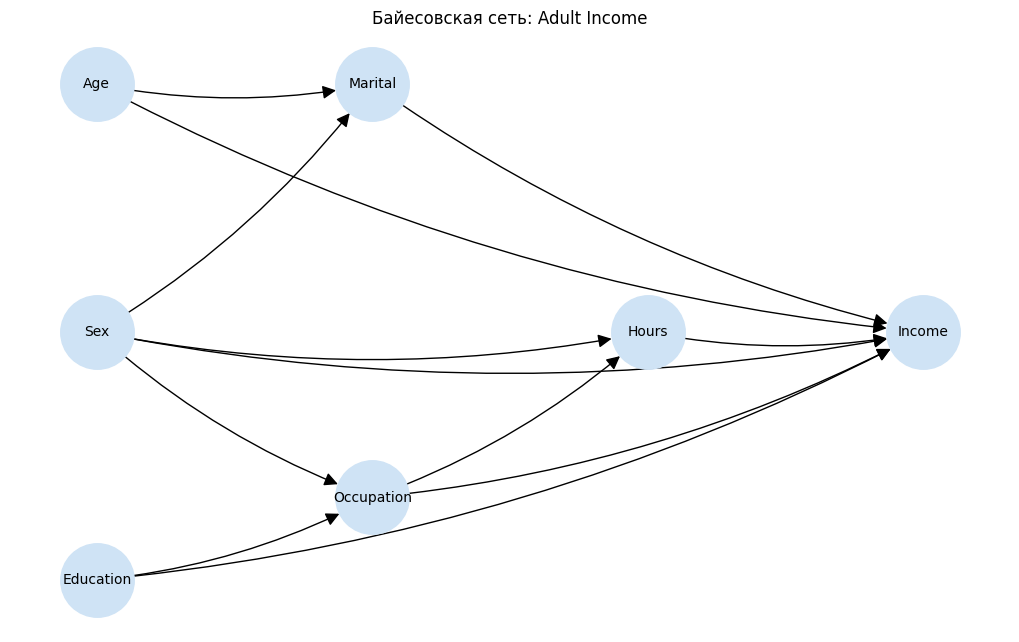

In [7]:
G = nx.DiGraph(edges)
pos = {
    "Age": (0, 3), "Sex": (0, 1.5), "Education": (0, 0),
    "Marital": (1, 3), "Occupation": (1, 0.5),
    "Hours": (2, 1.5), "Income": (3, 1.5),
}
plt.figure(figsize=(10, 6))
nx.draw(G, pos, with_labels=True, node_size=2800, node_color="#cfe3f5",
        font_size=10, arrowsize=20, connectionstyle="arc3,rad=0.1")
plt.title("Байесовская сеть: Adult Income")
plt.savefig("graph.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
from pgmpy.estimators import BayesianEstimator

est = BayesianEstimator(model, d)
# тут строим таблицу вероятностей

cpds = [
    est.estimate_cpd(node, prior_type="BDeu", equivalent_sample_size=10)
    for node in model.nodes()
]

model.cpds = []            # на случай повторного запуска
model.add_cpds(*cpds)

print("Модель корректна:", model.check_model())

for node in ["Marital", "Occupation"]:
    print(model.get_cpds(node))

C:\Users\Tema\AppData\Local\Temp\ipykernel_11660\4002872009.py:3: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  est = BayesianEstimator(model, d)


Модель корректна: True
+----------------------+-----+---------------------+
| Age                  | ... | Age(young)          |
+----------------------+-----+---------------------+
| Sex                  | ... | Sex(male)           |
+----------------------+-----+---------------------+
| Marital(married)     | ... | 0.2767478850836817  |
+----------------------+-----+---------------------+
| Marital(never)       | ... | 0.6821361710513351  |
+----------------------+-----+---------------------+
| Marital(was_married) | ... | 0.04111594386498318 |
+----------------------+-----+---------------------+
+--------------------------+-----+-------------------------+
| Education                | ... | Education(some_college) |
+--------------------------+-----+-------------------------+
| Sex                      | ... | Sex(male)               |
+--------------------------+-----+-------------------------+
| Occupation(blue_collar)  | ... | 0.4023657621105656      |
+--------------------------+

In [ ]:
import itertools
# 
def show_cpt(node):
    cpd = model.get_cpds(node)
    parents = cpd.variables[1:]
    states = cpd.state_names
    cols = list(itertools.product(*[states[p] for p in parents]))
    table = pd.DataFrame(
        cpd.get_values(),
        index=states[node],
        columns=pd.MultiIndex.from_tuples(cols, names=parents),
    )
    return table.round(3)

pd.set_option("display.width", 200)
print(show_cpt("Marital"))
# полная таблица вероятностей для martial

Age         middle        senior         young       
Sex         female   male female   male female   male
married      0.227  0.713  0.180  0.824  0.099  0.277
never        0.293  0.156  0.109  0.047  0.810  0.682
was_married  0.480  0.131  0.711  0.130  0.091  0.041


In [ ]:
from pgmpy.inference import VariableElimination
infer = VariableElimination(model)

# из сети
print(infer.query(["Occupation"], evidence={"Education": "bachelor_plus"}, show_progress=False))

# напрямую из данных
print(d[d["Education"] == "bachelor_plus"]["Occupation"].value_counts(normalize=True))

# проверка CPT Marital напрямую по данным (то, что мы видели выше)
sub = d[(d["Age"] == "young") & (d["Sex"] == "male")]
print(sub["Marital"].value_counts(normalize=True))
# првоерка что согласованы

+--------------------------+-------------------+
| Occupation               |   phi(Occupation) |
+==========================+===================+
| Occupation(blue_collar)  |            0.0679 |
+--------------------------+-------------------+
| Occupation(service)      |            0.0420 |
+--------------------------+-------------------+
| Occupation(white_collar) |            0.8902 |
+--------------------------+-------------------+
Occupation
white_collar    0.888539
blue_collar     0.070078
service         0.041383
Name: proportion, dtype: float64
Marital
never          0.682210
married        0.276736
was_married    0.041054
Name: proportion, dtype: float64


In [ ]:
from pgmpy.inference import VariableElimination
infer = VariableElimination(model)



# var -условие, evidence - услвоия 
def p(var, evidence=None):
    q = infer.query([var], evidence=evidence or {}, show_progress=False)
    return dict(zip(q.state_names[var], q.values.round(3)))

# --- Вопрос 1: P(Income=high | married, bachelor_plus) ---
# влияния браака на высоких доход
print("Q1")
print("  без evidence:                ", p("Income"))
print("  married:                     ", p("Income", {"Marital": "married"}))
print("  bachelor_plus:               ", p("Income", {"Education": "bachelor_plus"}))
print("  married + bachelor_plus:     ", p("Income", {"Marital": "married", "Education": "bachelor_plus"}))

# --- Вопрос 2: эффект пола при равных образовании и часах ---
# разрыв по доходу по половому призанку
# не зависит от пола а от факторов
print("Q2")
for sex in ["male", "female"]:
    print(f"  {sex}:                        ", p("Income", {"Sex": sex}))
    print(f"  {sex}, bachelor_plus, over40: ", p("Income", {"Sex": sex, "Education": "bachelor_plus", "Hours": "over40"}))

# --- Вопрос 3: Occupation при известном образовании ---
# как распределение професий зависит от образования
# более образованные получают больше
print("Q3")
print("  без evidence:", p("Occupation"))
for e in ["school", "hs_grad", "some_college", "bachelor_plus"]:
    print(f"  {e:14s}", p("Occupation", {"Education": e}))

Q1
  без evidence:                 {'high': np.float64(0.232), 'low': np.float64(0.768)}
  married:                      {'high': np.float64(0.413), 'low': np.float64(0.587)}
  bachelor_plus:                {'high': np.float64(0.412), 'low': np.float64(0.588)}
  married + bachelor_plus:      {'high': np.float64(0.686), 'low': np.float64(0.314)}
Q2
  male:                         {'high': np.float64(0.288), 'low': np.float64(0.712)}
  male, bachelor_plus, over40:  {'high': np.float64(0.582), 'low': np.float64(0.418)}
  female:                         {'high': np.float64(0.115), 'low': np.float64(0.885)}
  female, bachelor_plus, over40:  {'high': np.float64(0.35), 'low': np.float64(0.65)}
Q3
  без evidence: {'blue_collar': np.float64(0.328), 'service': np.float64(0.134), 'white_collar': np.float64(0.537)}
  school         {'blue_collar': np.float64(0.554), 'service': np.float64(0.251), 'white_collar': np.float64(0.194)}
  hs_grad        {'blue_collar': np.float64(0.476), 'service': np.fl

                    evidence  P(high)
0                     ничего    0.232
1  + Education=bachelor_plus    0.412
2          + Marital=married    0.686
3             + Hours=over40    0.769
4  + Occupation=white_collar    0.787
5               + Age=middle    0.804


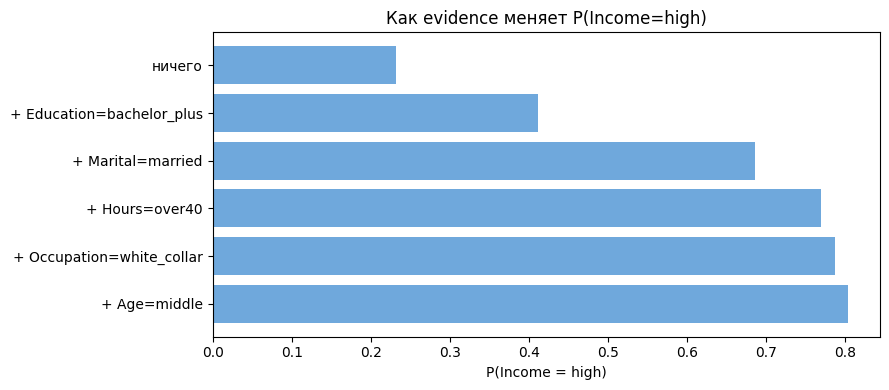

male {'high': np.float64(0.803), 'low': np.float64(0.197)}
female {'high': np.float64(0.812), 'low': np.float64(0.188)}


In [13]:
import matplotlib.pyplot as plt

steps = [
    ("ничего", {}),
    ("+ Education=bachelor_plus", {"Education": "bachelor_plus"}),
    ("+ Marital=married", {"Marital": "married"}),
    ("+ Hours=over40", {"Hours": "over40"}),
    ("+ Occupation=white_collar", {"Occupation": "white_collar"}),
    ("+ Age=middle", {"Age": "middle"}),
]

ev, rows = {}, []
for name, add in steps:
    ev = {**ev, **add}
    rows.append({"evidence": name, "P(high)": p("Income", ev)["high"]})
res = pd.DataFrame(rows)
print(res)

plt.figure(figsize=(9, 4))
plt.barh(res["evidence"][::-1], res["P(high)"][::-1], color="#6fa8dc")
plt.xlabel("P(Income = high)")
plt.title("Как evidence меняет P(Income=high)")
plt.tight_layout(); plt.savefig("evidence.png", dpi=150); plt.show()

# те же шаги, но для женщин и мужчин: эффект пола при полном выравнивании
full = {"Education": "bachelor_plus", "Marital": "married", "Hours": "over40",
        "Occupation": "white_collar", "Age": "middle"}
for sex in ["male", "female"]:
    print(sex, p("Income", {**full, "Sex": sex}))

In [ ]:
# удаляем ребро из графа

# поэтому реберо доавбляло мало полезнйо нфомрации
edges2 = [e for e in edges if e != ("Sex", "Income")]
model2 = BN(edges2)
est2 = BayesianEstimator(model2, d)
model2.add_cpds(*[est2.estimate_cpd(n, prior_type="BDeu", equivalent_sample_size=10)
                  for n in model2.nodes()])
print("Модель корректна:", model2.check_model())

infer2 = VariableElimination(model2)
def p2(var, evidence=None):
    q = infer2.query([var], evidence=evidence or {}, show_progress=False)
    return dict(zip(q.state_names[var], q.values.round(3)))

for sex in ["male", "female"]:
    print(sex, "| только пол:        ", p("Income", {"Sex": sex})["high"],
          "->", p2("Income", {"Sex": sex})["high"])
    print(sex, "| bachelor+over40:   ",
          p("Income", {"Sex": sex, "Education": "bachelor_plus", "Hours": "over40"})["high"],
          "->", p2("Income", {"Sex": sex, "Education": "bachelor_plus", "Hours": "over40"})["high"])
    print(sex, "| полное выравнивание:", p("Income", {**full, "Sex": sex})["high"],
          "->", p2("Income", {**full, "Sex": sex})["high"])

C:\Users\Tema\AppData\Local\Temp\ipykernel_11660\625518298.py:3: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  est2 = BayesianEstimator(model2, d)


Модель корректна: True
male | только пол:         0.288 -> 0.282
male | bachelor+over40:    0.582 -> 0.567
male | полное выравнивание: 0.803 -> 0.804
female | только пол:         0.115 -> 0.131
female | bachelor+over40:    0.35 -> 0.41
female | полное выравнивание: 0.812 -> 0.804
